### isme apne ek topic pe llm se out line likhwani hai and then us outline se apne ko blog generate krwana hai

In [21]:
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from typing import TypedDict
from langchain_core.output_parsers import StrOutputParser

In [22]:
parser = StrOutputParser()

In [3]:
load_dotenv()  # Load environment variables from .env file

True

In [4]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [ ]:
# Defining state for graph 

class BlogState(TypedDict):
    title: str
    content: str
    outline: str
    


In [ ]:
def create_outline(state: BlogState) -> BlogState:
    prompt = f"Generate a detailed outline for a blog on the topic -> {state['title']}"
    
    # LLM calling
    
    outline = model.invoke(prompt).content
    
    state['outline'] = outline
    
    return state

In [23]:
def generate_blog(state: BlogState) -> BlogState:
    prompt= f"Write a detailed blog on the title - {state['title']} using the following outline -> \n {state['outline']}"
    
    #LLM calling
    
    content = model.invoke(prompt)
    
    parsed_output = parser.invoke(content)
    
    state['content'] = parsed_output
    
    return state

In [24]:
# Defining the graph 

graph = StateGraph(BlogState)

# add nodes to the graph

graph.add_node('create_outline', create_outline)
graph.add_node('generate_blog', generate_blog)

#add edges to the graph 

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'generate_blog')
graph.add_edge('generate_blog', END)

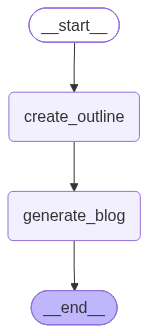

In [25]:
#compile the graph 
graph.compile()

In [26]:
workflow = graph.compile()

In [ ]:
initial_state = {'title': 'Rise of Virat Kohli'}

final_result = workflow.invoke(initial_state)

print(final_result)

{'title': 'Rise of Virat Kohli', 'content': '# The Rise of Virat Kohli – From Mumbai’s Streets to Cricketing Legend  \n\n> *“The only way to win is to never give up.”* – Virat Kohli  \n\n---\n\n## 1. Hook & Thesis  \n\nPicture the 2008 ICC Under‑19 World Cup final: a packed stadium in New Zealand, rain‑slick wickets, and a 19‑year‑old Virat Kohli smashing a 76* off 59 balls. The crowd erupted, the scoreboard glowed, and a future icon was already making history.  \n\n**Thesis:** Virat Kohli’s ascent from a street‑cricket enthusiast in Mumbai to a global cricketing legend is a tale of relentless ambition, disciplined work‑ethic, and an unquenchable passion that reshaped Indian cricket.  \n\n---\n\n## 2. Early Life & Foundations  \n\n| Section | Key Points |\n|---------|------------|\n| **Birth & Family** | Born 5\u202fNov\u202f1988, Delhi. Father Anil Kohli, a businessman; mother Saroj. Early exposure to cricket culture through family gatherings. |\n| **Mumbai Relocation** | Moved to Mum

In [30]:
print(final_result['content'])


# The Rise of Virat Kohli – From Mumbai’s Streets to Cricketing Legend  

> *“The only way to win is to never give up.”* – Virat Kohli  

---

## 1. Hook & Thesis  

Picture the 2008 ICC Under‑19 World Cup final: a packed stadium in New Zealand, rain‑slick wickets, and a 19‑year‑old Virat Kohli smashing a 76* off 59 balls. The crowd erupted, the scoreboard glowed, and a future icon was already making history.  

**Thesis:** Virat Kohli’s ascent from a street‑cricket enthusiast in Mumbai to a global cricketing legend is a tale of relentless ambition, disciplined work‑ethic, and an unquenchable passion that reshaped Indian cricket.  

---

## 2. Early Life & Foundations  

| Section | Key Points |
|---------|------------|
| **Birth & Family** | Born 5 Nov 1988, Delhi. Father Anil Kohli, a businessman; mother Saroj. Early exposure to cricket culture through family gatherings. |
| **Mumbai Relocation** | Moved to Mumbai at 14. Enrolled at St. Andrew’s College, where he met mentor coach Nit

In [31]:
print(final_result['outline'])

# Blog Outline: **The Rise of Virat Kohli – From Mumbai’s Streets to Cricketing Legend**

---

## 1. Hook & Thesis  
- **Opening anecdote**: A snapshot of the 2008 Under‑19 World Cup final – Kohli’s 76* and the crowd’s roar.  
- **Thesis statement**: Virat Kohli’s ascent is a story of relentless ambition, disciplined work‑ethic, and an unquenchable passion for the game that reshaped Indian cricket.

---

## 2. Early Life & Foundations  
| Section | Key Points |
|---------|------------|
| **Birth & Family** | Born 5 Nov 1988, Delhi; father Anil Kohli, a businessman; mother Saroj; early exposure to cricket culture. |
| **Mumbai Relocation** | Moved to Mumbai at 14; joined St. Andrew’s College; early mentors: coach Nitin Sharma. |
| **First Steps in Cricket** | Played street cricket; joined the “BCCI Academy” at 15; first wicket‑taking match at 17. |
| **Academic vs. Cricket** | Balancing school with training; early decision to pursue cricket full‑time. |
| **Influences** | Inspiration fr